In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.svm import SVC

In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../../../Edge-IIoTset_ML-112.csv')

In [4]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [5]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_label']

In [6]:
# Load precomputed selected features
feature_list_path = "../selected_features_binary_mi.pkl"
with open(feature_list_path, "rb") as f:
    selected_features = pickle.load(f)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)

In [8]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (121796, 30)
X_test shape: (30449, 30)


In [9]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
def svm_model():
    model = SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        probability=True,
        random_state=42
    )
    return model

model = svm_model()

In [11]:
# Train the model
model.fit(X_train, y_train)

SVC(probability=True, random_state=42)

In [12]:
# Predict on the test set
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, np.round(y_pred), target_names=['No Intrusion', 'Intrusion']))

Accuracy: 0.9999671581989557
Classification Report:
              precision    recall  f1-score   support

No Intrusion       1.00      1.00      1.00      4837
   Intrusion       1.00      1.00      1.00     25612

    accuracy                           1.00     30449
   macro avg       1.00      1.00      1.00     30449
weighted avg       1.00      1.00      1.00     30449



In [13]:
# y_pred_proba already contains probabilities for binary classification
y_pred_proba = model.predict(X_test)  # Probabilities for class 1
auc = roc_auc_score(y_test, y_pred_proba)

print(f"AUC: {auc:.4f}")

AUC: 1.0000


In [14]:
n_samples = min(100, len(X_test))
total_time = 0.0

for i in range(n_samples):
    sample = X_test[i].reshape(1, -1)  # Single sample
    start_time = time.time()
    _ = model.predict(sample)
    total_time += time.time() - start_time

avg_inference_time = total_time / n_samples
print(f"Average inference time per sample: {avg_inference_time:.6f} seconds")

Average inference time per sample: 0.000658 seconds


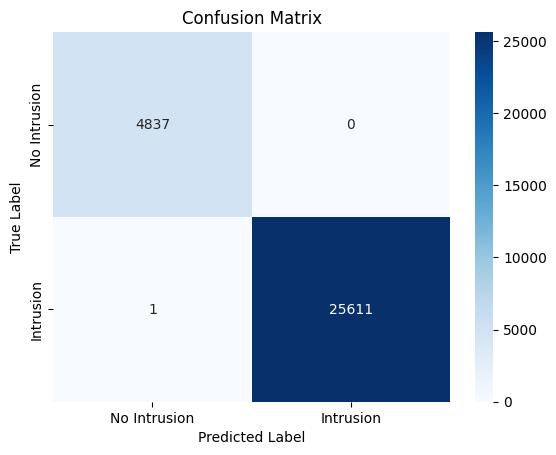

In [15]:
conf_mat = confusion_matrix(y_test, np.round(y_pred))

# Define the class labels
class_labels = ['No Intrusion', 'Intrusion']

# Create a heatmap plot of the confusion matrix
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)

# Set the plot labels and title
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')

# Show the plot
plt.show()
# plt.savefig('con_max.jpg')

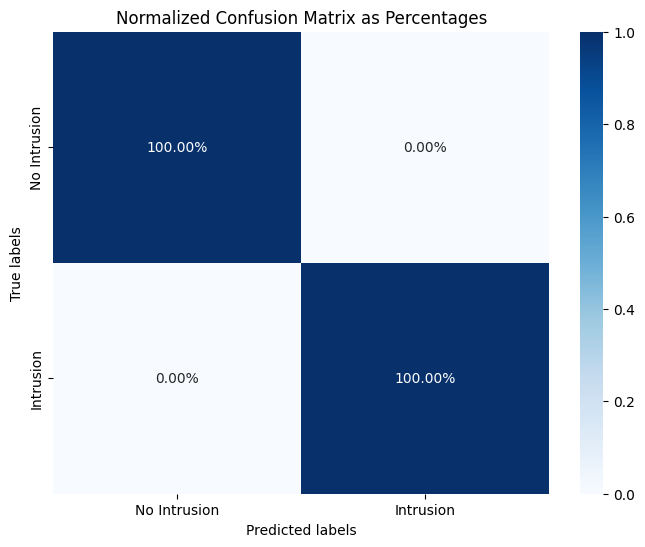

In [16]:
# Predict the test set
y_pred = (y_pred > 0.5)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
# Define the class labels
class_labels = ['No Intrusion', 'Intrusion']
# Print confusion matrix as heatmap with percentages
plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, cmap='Blues', xticklabels=class_labels, yticklabels=class_labels, fmt='.2%')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')